In [1]:
import os

# Need to load in Keras 2 in order to use DenseVariational class which is required for BNN in Keras example
os.environ["TF_USE_LEGACY_KERAS"] = "1"


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes
import tensorflow as tf
import tf_keras
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_probability as tfp
from scipy.stats import Normal



# Features are normalized by default
diabetes_sklearn = load_diabetes()
diabetes_df = pd.DataFrame(data = diabetes_sklearn.data,
                           columns = diabetes_sklearn.feature_names)

diabetes_df['target'] = diabetes_sklearn.target
print(diabetes_df.head(5))
print('Shape:', diabetes_df.shape)





        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
Shape: (442, 11)


In [3]:
y_m = diabetes_df['target'].mean()
y_std = diabetes_df['target'].std()

# Normalize the target around its mean
print('Before: ', diabetes_df['target'])
diabetes_df['target'] = (diabetes_df['target'] - y_m) / y_std

print('After: ', diabetes_df['target'])

Before:  0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
437    178.0
438    104.0
439    132.0
440    220.0
441     57.0
Name: target, Length: 442, dtype: float64
After:  0     -0.014703
1     -1.000525
2     -0.144416
3      0.698721
4     -0.222244
         ...   
437    0.335524
438   -0.624356
439   -0.261158
440    0.880320
441   -1.234009
Name: target, Length: 442, dtype: float64


In [34]:
train_df, test_df = train_test_split(diabetes_df, test_size = 0.2, random_state = 11242026) # create train and test set, shuffled
hidden_units = [8, 8]
learning_rate = 0.001

def tf_translate_pandas(df, batch_size=32):
    df = df.copy()
    # create a dictionary of 1D arrays, each array are columns of the dataframe
    labels = df.pop('target') # the  target column
    features = {name : df[name].values.astype("float32") for name in df.columns}
    ds = tf.data.Dataset.from_tensor_slices((features, labels.values.astype("float32"))) # TensorFlow dataset

    return ds.batch(batch_size) # return in batches (useful for high volume datasets)

train_df = tf_translate_pandas(train_df)
test_df = tf_translate_pandas(test_df)


def run_experiment(model, loss, train_dataset, test_dataset):

    model.compile(
        optimizer=keras.optimizers.RMSprop(learning_rate=learning_rate),
        loss=loss,
        metrics=[keras.metrics.RootMeanSquaredError()],
    )

    print("Start training the model...")
    model.fit(train_dataset, epochs=num_epochs, validation_data=test_dataset)
    print("Model training finished.")
    _, rmse = model.evaluate(train_dataset, verbose=0)
    print(f"Train RMSE: {round(rmse, 3)}")

    print("Evaluating model performance...")
    _, rmse = model.evaluate(test_dataset, verbose=0)
    print(f"Test RMSE: {round(rmse, 3)}")

feats = diabetes_sklearn.feature_names

def create_model_inputs():
    inputs = {}
    for feature_name in feats:
        inputs[feature_name] = layers.Input(
            name=feature_name, shape=(1, ), dtype = tf.float32
        )
    return inputs


In [ ]:
# TODO  create experimental Bayes NN for diabetes dataset
'''
    @ Normalize and test diabetes dataset
    @ Create baseline model to compare against Bayesian NN 
'''
train_df

<_BatchDataset element_spec=({'age': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 'sex': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 'bmi': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 'bp': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 's1': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 's2': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 's3': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 's4': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 's5': TensorSpec(shape=(None,), dtype=tf.float32, name=None), 's6': TensorSpec(shape=(None,), dtype=tf.float32, name=None)}, TensorSpec(shape=(None,), dtype=tf.float32, name=None))>


In [25]:
inputs = create_model_inputs()
print(feats)
print(inputs)

## Experiment baseline (regular Neural Network)

def create_baseline_model():
    inputs = create_model_inputs()
    input_values = [value for _, value in sorted(inputs.items())]
    features = keras.layers.concatenate(input_values)
    features = layers.BatchNormalization()(features)

    # Create hidden layers with deterministic weights using the Dense layer.
    for units in hidden_units:
        features = layers.Dense(units, activation="sigmoid")(features)
    # The output is deterministic: a single point estimate.
    outputs = layers.Dense(units=1)(features)
    print(type(inputs))
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

num_epochs = 100
mse_loss = keras.losses.MeanSquaredError()
baseline_model = create_baseline_model()
run_experiment(baseline_model, mse_loss, train_df, test_df)



['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
{'age': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 'age')>, 'sex': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 'sex')>, 'bmi': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 'bmi')>, 'bp': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 'bp')>, 's1': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 's1')>, 's2': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 's2')>, 's3': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 's3')>, 's4': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 's4')>, 's5': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 's5')>, 's6': <KerasTensor: shape=(None, 1) dtype=float32 (created by layer 's6')>}
<class 'dict'>
Start training the model...
Epoch 1/100
12/12 [==============================] - 0s 8ms/step - loss: 1.0926 - root_mean_squared_error: 1.0453 - val_loss: 

In [ ]:
sample = 10
# split the batch dataset into single elements then shuffle then rebatch it and produce the first 10 
examples, targets = list(test_df.unbatch().shuffle(1000).batch(sample))[
    0
]

predicted = baseline_model(examples).numpy()
for idx in range(sample):
    print(f"Predicted: {round(float(predicted[idx][0]), 1)} - Actual: {targets[idx]}")

scaled_predictions = baseline_model(examples, training=False).numpy() * y_std + y_m
scaled_targets = targets * y_std + y_m

print("\n")

for idx in range(sample):
    print(f"Predicted: {round(float(scaled_predictions[idx][0]), 1)} - Actual: {round(float(scaled_targets[idx]), 1)}")

print("Test baseline RMSE:", 0.78)


Predicted: -0.5 - Actual: 1.2954031229019165
Predicted: -0.6 - Actual: -1.2599519491195679
Predicted: -0.0 - Actual: 0.2836381196975708
Predicted: 0.6 - Actual: -0.3908718228340149
Predicted: 0.9 - Actual: 1.3732311725616455
Predicted: 0.3 - Actual: -0.5854420065879822
Predicted: -0.6 - Actual: -1.4285794496536255
Predicted: 0.7 - Actual: 0.5041509866714478
Predicted: 0.9 - Actual: 1.6196867227554321
Predicted: 0.3 - Actual: 1.3862024545669556


Predicted: 112.2 - Actual: 252.0
Predicted: 104.2 - Actual: 55.0
Predicted: 152.1 - Actual: 174.0
Predicted: 196.1 - Actual: 122.0
Predicted: 221.1 - Actual: 258.0
Predicted: 173.4 - Actual: 107.0
Predicted: 104.6 - Actual: 42.0
Predicted: 206.8 - Actual: 191.0
Predicted: 222.1 - Actual: 277.0
Predicted: 173.7 - Actual: 259.0
Test baseline RMSE: 0.78


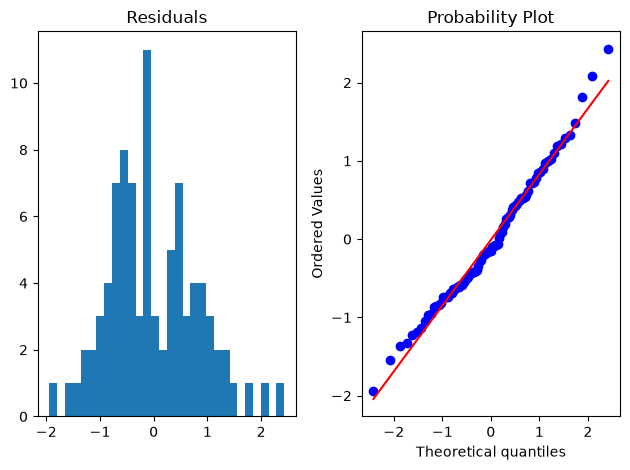

In [27]:
import matplotlib.pyplot as plt
## After our first baseline model we look at the residuals to decide likelihood 
### Another way to it
from scipy.stats import probplot

# split the batch dataset into single elements then shuffle then rebatch it and produce the first 10 
x_test, y_test = list(test_df.unbatch().shuffle(1000).batch(diabetes_df.shape[0]))[
    0
]

preds = baseline_model(x_test).numpy().flatten()
resid = y_test - preds

fig, ax = plt.subplots(1,2)
ax[0].hist(resid, bins = 30)
ax[0].set_title("Residuals")
probplot(resid, plot = ax[1])

plt.tight_layout()
plt.show()

# looks Normal

In [ ]:
# Experiment 2: Bayesian NN
# Captures epistemic uncertainity - due to limited training data
# learns weight distributions instead of weight *values* 
# sample from weight distribution to produce outputs based on an input, which will tell us the weight uncertainty

# TODO  create experimental Bayes NN for diabetes dataset
'''
    @ Define Prior and Posterior Distribution
    @ Figure out priors for the diabetes dataset
    @ Implement Monte Carlo simulations for computing posterior
    @ Implement Monte Carlo simulations for sampling predictions from posterior 
'''

## Experiment 2: Bayesian Neural Networks

- When defining the prior and likelihood, think about the Data Generating Process (DGP!)
- **Likelihood:** the data is generated, given parameters: what is the model that is creating the data?
- **Priors:** think about the uncertainty around the model's parameters: what values can the parameters take before seeing the data?
    - Think: what values can the prior distribution take to produce the parameters that fit our likelihood model?
    - In normal regression and other modeling, the priors can be reasoned by extraneous knowledge: 
        - If Robert Covington has a record of 35% average accuracy, then the prior parameters will be a = 35, b = 65 or a = 3.5, b = 6.5.
    - In Neural Networks, the prior parameters can only be thought in the context of the functions which the network computes
        - If the outputs of a neural network that has been trained on normalized data has the range [-1, 2], then the prior distribution should produce outputs that fall roughly on the scale of that data

### Baysian Review:
From PSTAT 115:
On Nov 18, 2017, an NBA basketball player Robert Covington had made 49 out of 100 three point shot
attempts
At that time his three point field goal percentage, 0.49, was the best in the league and would have ranked
in the top ten of all time

Estimating True shooting skill:

**Frequentist Approach**:

$$
\hat{\theta}_{\textrm{MLE}} = \frac{49}{100} = 0.49
$$

**Bayesian Approach**:
Make assumption of independence, like the Frequentist and infer that the distribution of each shot is a Bernoulli trial with success probability of $\theta$ with $y$ out of $n$ attempts:

The Bernoulli likelihood is: $\mathcal{L}(\theta) \propto \theta^y(1-\theta)^{(n-y)}$

Then assume a *no knowledge* prior (Uniform prior), $\theta$ lives in $[0,1]$, a fail or success so a no knowledge prior will look like: 

$p(\theta) \propto 1$ for $\theta \in [0,1]$ 

Using Bayes' rule and under assumption of independence, multiply the likelihood and prior to get the posterior:

$$
p(\theta | y) \propto \mathcal{L}(\theta) \cdot p(\theta) = \theta^y(1-\theta)^{(n-y)} \cdot 1
$$

The kernel, $\theta^y(1-\theta)^{(n-y)}$, looks like binomial pdf but is over $y$ not $\theta$ 

$$
\int_0^1 k \theta^y (1 - \theta)^{n-y} d \theta = 1 \ \ \rm{(Beta Distribution)}
$$

where 
 - $a - 1 = y$ 
 - $b - 1 = n - y$
 - $k = 1/B(a,b)$

so $\theta | y \sim Beta(y + 1, n - y + 1)$

Note, this is a special case of the Beta-Binomial conjugate pair. 
With Beta(1,1), equivalent to Unif(0,1), prior producing a Beta($y+1, n - y + 1$) posterior

In [ ]:
# Define prior distribution as Normal of mean = 0 and stdev = 1
# Let's assume prior before looking at the data, that diabetes outcomes follows a normal distribution due to its small size

# kernel size = inputs x units
# bias size = units
def prior(kernel_size, bias_size, dtype=None):
    n = kernel_size + bias_size # total number of weights and biases
    prior_model = keras.Sequential(
        [
            tfp.layers.DistributionLambda(
                # Uses the lambda function to assign each weight an independent N(0,1)
                # no training parameters, it is fixed
                lambda t : tfp.distributions.MultivariateNormalDiag(
                    # loc = mu, scale_diag = sigma
                    loc = tf.zeros(n), scale_diag = tf.ones(n) 
                    )
                )
            ]
    )
    return prior_model

def posterior(kernel_size, bias_size, dtype=None):
    n = kernel_size + bias_size
    # Normal over the layer's weights with trainable mean and full covariance
    # full covariance between weights allows for better transparency of our uncertainty
    posterior_model = keras.Sequential(
        [
            # VariableLayer creates a trainable tensor model
            # holds the parameters of the posterior, what we are training for
            tfp.layers.VariableLayer( 
                # the trainable parameters are n + n(n+1)/2 since it's the 
                # vector of weights for the mean (n) + the covariance matrix which is a lower triangular matrix with n(n+1)/2 entries
                # MultivariateNormalTriL: A d-variate MVNTriL Keras layer from d + d * (d + 1) // 2 params.
                tfp.layers.MultivariateNormalTriL.params_size(n), dtype = dtype 
            ),
            tfp.layers.MultivariateNormalTriL(n),
        ]
    )
    return posterior_model

# diagonal model:

def posteriorDiag(kernel_size, bias_size, dtype=None):
    n = kernel_size + bias_size
    posterior_model = keras.Sequential(
        [
            # trainable parameters will be the vector of weights for the mean + vector of weights for the standard dev
            tfp.layers.VariableLayer(2 * n) ,
            tfp.layers.DistributionLambda(
                lambda t : tfp.distributions.MultivariateNormalDiag(
                    loc =  t[..., :n],
                    scale_diag = 1e-5 + tf.nn.softplus(t[..., n:] - 3.0),
                    # softplus is an activation function, similar to relu and its derivative is the sigmoid function
                    # soft plus = log(1 + exp(x)), which is smooth version of relu and is always positive and a nonzero gradient everywhere
                    # add 1e-5 as a floor and multiply t[..., :n] (the means) by 0.05 to shrink raw values and avoid being unstable since otherwise its outputs will 
                    # be far from t
                )
            ),
        ]
    )
    return posterior_model

def create_bnn_model(train_size):
    inputs = create_model_inputs()
    features = keras.layers.concatenate(list(inputs.values()))
    features = layers.BatchNormalization()(features) # normalize the features, doesn't matter if the features have already been normalized or scaled

    # Create hidden layers with weight uncertainty using the DenseVariation layer
    for units in hidden_units:
        features = tfp.layers.DenseVariational(
            units = units,
            make_prior_fn = prior,
            make_posterior_fn = posterior,
            kl_weight = 1 / train_size,
            activation = 'sigmoid',
        )(features)

    # The outputs here are deterministic
    outputs = layers.Dense(units = 1)(features)
    model = keras.Model(inputs = inputs, outputs = outputs)
    return model    


In [117]:
create_model_inputs()

{'age': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=age>,
 'sex': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=sex>,
 'bmi': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=bmi>,
 'bp': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=bp>,
 's1': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=s1>,
 's2': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=s2>,
 's3': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=s3>,
 's4': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=s4>,
 's5': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=s5>,
 's6': <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=s6>}

In [31]:
# we experiment with creating a bnn model using a small training sample size
num_epochs = 500
batch_size = 32
train_sample_size = int(len(diabetes_df) * 0.24 ) # let's take 30% of our training dataset
small_train = train_df.unbatch().take(train_sample_size).batch(batch_size)

bnn_model_small = create_bnn_model(train_sample_size)
run_experiment(bnn_model_small, mse_loss, small_train, test_df)


Start training the model...
Epoch 1/500
4/4 [==============================] - 1s 134ms/step - loss: 1.2292 - root_mean_squared_error: 1.0866 - val_loss: 1.1565 - val_root_mean_squared_error: 1.0547
Epoch 2/500
4/4 [==============================] - 0s 7ms/step - loss: 1.2051 - root_mean_squared_error: 1.0635 - val_loss: 1.2658 - val_root_mean_squared_error: 1.0857
Epoch 3/500
4/4 [==============================] - 0s 12ms/step - loss: 1.1661 - root_mean_squared_error: 1.0410 - val_loss: 1.2896 - val_root_mean_squared_error: 1.1007
Epoch 4/500
4/4 [==============================] - 0s 8ms/step - loss: 1.2465 - root_mean_squared_error: 1.0862 - val_loss: 1.1776 - val_root_mean_squared_error: 1.0521
Epoch 5/500
4/4 [==============================] - 0s 6ms/step - loss: 1.2168 - root_mean_squared_error: 1.0707 - val_loss: 1.1849 - val_root_mean_squared_error: 1.0543
Epoch 6/500
4/4 [==============================] - 0s 7ms/step - loss: 1.1199 - root_mean_squared_error: 1.0279 - val_loss: 

In [89]:
def compute_predictions(model, iterations = 100):
    predicted = []
    for _ in range(iterations):
        predicted.append(model(examples, training=False).numpy())
    predicted = np.concatenate(predicted, axis = 1)

    prediction_mean = np.mean(predicted, axis =1).tolist()
    prediction_min = np.min(predicted, axis=1).tolist()
    prediction_max = np.max(predicted, axis=1).tolist()
    prediction_range = (np.max(predicted, axis=1) - np.min(predicted, axis =1)).tolist()

    for idx in range(sample):
        print(
            f"Predictions mean: {round(prediction_mean[idx], 2)}, "
            f"min: {round(prediction_min[idx], 2)}, "
            f"max: {round(prediction_max[idx], 2)}, "
            f"range: {round(prediction_range[idx], 2)} - "
            f"Actual: {targets[idx]}"
        )

def predictive_summary(model, dataset, iterations = 100):
    x, y = list(dataset.unbatch().batch(1000))[0] # feature weights and targets extracted from full set
    preds = np.stack([model(x, training=False).numpy().ravel() for _ in range(iterations)]) # make predictions from 100 draws
    y = y.numpy().ravel() # flatten our target
    mean_pred, sd_pred = preds.mean(axis=0), preds.std(axis=0)
    rmse = np.sqrt(np.mean((mean_pred - y)**2)) # calculate the rmse manually
    low, high = np.percentile(preds, [2.5,97.5], axis=0) # get the 90% interval of predictions
    coverage = np.mean((low <= y) & (high >= y)) # compare the 90% interval to the test targets
    return rmse, sd_pred.mean(), coverage

compute_predictions(bnn_model_small)

Predictions mean: 0.0, min: -0.38, max: 0.4, range: 0.77 - Actual: 1.2954031229019165
Predictions mean: -0.04, min: -0.47, max: 0.24, range: 0.71 - Actual: -1.2599519491195679
Predictions mean: 0.02, min: -0.25, max: 0.34, range: 0.59 - Actual: 0.2836381196975708
Predictions mean: 0.03, min: -0.22, max: 0.34, range: 0.56 - Actual: -0.3908718228340149
Predictions mean: 0.04, min: -0.25, max: 0.32, range: 0.57 - Actual: 1.3732311725616455
Predictions mean: 0.01, min: -0.21, max: 0.31, range: 0.52 - Actual: -0.5854420065879822
Predictions mean: -0.01, min: -0.46, max: 0.33, range: 0.8 - Actual: -1.4285794496536255
Predictions mean: 0.03, min: -0.22, max: 0.33, range: 0.55 - Actual: 0.5041509866714478
Predictions mean: 0.06, min: -0.16, max: 0.34, range: 0.5 - Actual: 1.6196867227554321
Predictions mean: 0.03, min: -0.23, max: 0.34, range: 0.58 - Actual: 1.3862024545669556


In [ ]:
# Full set
num_epochs = 500
bnn_model_full = create_bnn_model(len(diabetes_df) * 0.8)
run_experiment(bnn_model_full, mse_loss, train_df, test_df)

Start training the model...
Epoch 1/500
12/12 [==============================] - 1s 33ms/step - loss: 2.2523 - root_mean_squared_error: 1.4838 - val_loss: 2.5545 - val_root_mean_squared_error: 1.5814
Epoch 2/500
12/12 [==============================] - 0s 3ms/step - loss: 2.2356 - root_mean_squared_error: 1.4765 - val_loss: 2.1960 - val_root_mean_squared_error: 1.4643
Epoch 3/500
12/12 [==============================] - 0s 3ms/step - loss: 2.1470 - root_mean_squared_error: 1.4495 - val_loss: 2.1214 - val_root_mean_squared_error: 1.4375
Epoch 4/500
12/12 [==============================] - 0s 3ms/step - loss: 1.7106 - root_mean_squared_error: 1.2865 - val_loss: 1.8347 - val_root_mean_squared_error: 1.3365
Epoch 5/500
12/12 [==============================] - 0s 3ms/step - loss: 1.6132 - root_mean_squared_error: 1.2524 - val_loss: 2.1404 - val_root_mean_squared_error: 1.4498
Epoch 6/500
12/12 [==============================] - 0s 3ms/step - loss: 1.6835 - root_mean_squared_error: 1.2800 - 

In [36]:
compute_predictions(bnn_model_full)

Predictions mean: -0.01, min: -0.78, max: 0.67, range: 1.45 - Actual: 1.2954031229019165
Predictions mean: -0.77, min: -1.1, max: -0.27, range: 0.82 - Actual: -1.2599519491195679
Predictions mean: 0.0, min: -0.79, max: 0.72, range: 1.51 - Actual: 0.2836381196975708
Predictions mean: 0.55, min: 0.04, max: 0.97, range: 0.93 - Actual: -0.3908718228340149
Predictions mean: 0.9, min: 0.12, max: 1.21, range: 1.09 - Actual: 1.3732311725616455
Predictions mean: 0.48, min: -0.22, max: 0.98, range: 1.2 - Actual: -0.5854420065879822
Predictions mean: -0.73, min: -1.07, max: -0.22, range: 0.85 - Actual: -1.4285794496536255
Predictions mean: 0.67, min: -0.38, max: 1.1, range: 1.47 - Actual: 0.5041509866714478
Predictions mean: 1.0, min: 0.32, max: 1.21, range: 0.89 - Actual: 1.6196867227554321
Predictions mean: 0.24, min: -0.42, max: 0.77, range: 1.19 - Actual: 1.3862024545669556


In [ ]:
rmse_small, sd_small, cov_small = predictive_summary(bnn_model_small, test_df)
rmse, sd, cov = predictive_summary(bnn_model_full, test_df)
print(f"RMSE of mean: {rmse:.3f}, average prediction of std: {sd:.3f}, and percentage of test targets that fall within 95% prediction interval: {cov:.2f}")

print(f"RMSE of mean: {rmse_small:.3f}, average prediction of std: {sd_small:.3f}, and percentage of test targets that fall within 95% prediction interval: {cov_small:.2f}")

RMSE of mean: 0.772, average prediction of std: 0.227, and percentage of test targets that fall within 90% prediction interval: 0.37
RMSE of mean: 1.027, average prediction of std: 0.123, and percentage of test targets that fall within 90% prediction interval: 0.10


In [ ]:
def create_probablistic_bnn_model(train_size):
    inputs = create_model_inputs()
    features = keras.layers.concatenate(list(inputs.values()))
    features = layers.BatchNormalization()(features)

    # Create hidden layers with weight uncertainty using the DenseVariational layer.
    for units in hidden_units:
        features = tfp.layers.DenseVariational(
            units=units,
            make_prior_fn=prior,
            make_posterior_fn=posterior,
            kl_weight=1 / train_size,
            activation="sigmoid",
        )(features)

    # Create a probabilistic output (Normal distribution), and use the `Dense` layer
    # to produce the parameters of the distribution.
    # We set units=2 to learn both the mean and the variance of the Normal distribution.
    distribution_params = layers.Dense(units=2)(features)
    outputs = tfp.layers.IndependentNormal(1)(distribution_params)

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

def negative_loglikelihood(targets, estimated_distribution):
    return -estimated_distribution.log_prob(targets)


In [46]:

num_epochs = 1000
prob_bnn_model = create_probablistic_bnn_model(len(diabetes_df) * 0.8)
run_experiment(prob_bnn_model, negative_loglikelihood, train_df, test_df)



Start training the model...
Epoch 1/1000
12/12 [==============================] - 2s 35ms/step - loss: 1.7115 - root_mean_squared_error: 1.2395 - val_loss: 1.9766 - val_root_mean_squared_error: 1.1883
Epoch 2/1000
12/12 [==============================] - 0s 3ms/step - loss: 1.6728 - root_mean_squared_error: 1.2892 - val_loss: 1.6116 - val_root_mean_squared_error: 1.2540
Epoch 3/1000
12/12 [==============================] - 0s 3ms/step - loss: 1.9722 - root_mean_squared_error: 1.1626 - val_loss: 1.9811 - val_root_mean_squared_error: 1.4785
Epoch 4/1000
12/12 [==============================] - 0s 3ms/step - loss: 1.7220 - root_mean_squared_error: 1.3101 - val_loss: 1.6792 - val_root_mean_squared_error: 1.3515
Epoch 5/1000
12/12 [==============================] - 0s 3ms/step - loss: 1.9081 - root_mean_squared_error: 1.3233 - val_loss: 1.6325 - val_root_mean_squared_error: 1.4222
Epoch 6/1000
12/12 [==============================] - 0s 3ms/step - loss: 1.5978 - root_mean_squared_error: 1.3

In [75]:
x, y = list(test_df.unbatch().batch(1000))[0]
iterations = 100
means, sds = [], []
for _ in range(iterations):
    prediction_distributions = prob_bnn_model(x, training = False)
    means.append(prediction_distributions.mean().numpy().ravel()) # build vector of weights for means
    sds.append(prediction_distributions.stddev().numpy().ravel())

means = np.stack(means) # stack the weights into rows = # of iterations
sds = np.stack(sds) 


prediction_mean = means.mean(axis=0) # the posterior predictive means, the posterior mean for each iteration
prediction_stdv = sds.mean(axis=0)
rmse = np.sqrt(np.mean((prediction_mean - y)**2))

# The 95% CI is computed as mean ± (1.96 * stdv)
upper = (prediction_mean + (1.96 * prediction_stdv))
lower = (prediction_mean - (1.96 * prediction_stdv))
cov = np.mean(((y >= lower) & (y <= upper)))

for idx in range(sample):
    print(
        f"Prediction mean: {round(prediction_mean[idx], 2):.3f}, "
        f"stddev: {round(prediction_stdv[idx], 2):.3f}, "
        f"95% CI: [{round(upper[idx], 2):.3f} - {round(lower[idx], 2):.3f}]"
        f" - Actual: {y[idx]:.3f}"
    )

print(f"RMSE of mean: {rmse:.3f}, average prediction of std: {np.mean(prediction_stdv):.3f}, 95% coverage: {cov:.2f}")

Prediction mean: 0.050, stddev: 0.780, 95% CI: [1.570 - -1.480] - Actual: -0.793
Prediction mean: -0.740, stddev: 0.680, 95% CI: [0.600 - -2.080] - Actual: -1.260
Prediction mean: -0.550, stddev: 0.710, 95% CI: [0.840 - -1.930] - Actual: 0.206
Prediction mean: 0.950, stddev: 0.900, 95% CI: [2.720 - -0.820] - Actual: 2.385
Prediction mean: -0.470, stddev: 0.720, 95% CI: [0.930 - -1.880] - Actual: 0.751
Prediction mean: -0.400, stddev: 0.720, 95% CI: [1.010 - -1.820] - Actual: -0.637
Prediction mean: -0.350, stddev: 0.730, 95% CI: [1.090 - -1.780] - Actual: -0.106
Prediction mean: 0.500, stddev: 0.840, 95% CI: [2.140 - -1.140] - Actual: -0.391
Prediction mean: 0.390, stddev: 0.820, 95% CI: [2.000 - -1.220] - Actual: 1.075
Prediction mean: -0.740, stddev: 0.680, 95% CI: [0.610 - -2.080] - Actual: -0.897
RMSE of mean: 0.774, average prediction of std: 0.779, 95% coverage: 0.97


In [ ]:
print(f"(probabilistic) RMSE of mean: {rmse:.3f}, average prediction of std: {np.mean(prediction_stdv):.3f}, 95% coverage: {cov:.2f}")
# rmse_epi, sd_epi, cov_epi = predictive_summary(bnn_model_full, test_df)
print(f"(epistemic) RMSE of  mean: {rmse_epi:.3f}, average prediction of std: {sd_epi:.3f}, and percentage of test targets that fall within 95% prediction interval: {cov_epi:.2f}")

predicted = baseline_model(x).numpy().ravel()
rmse_baseline = np.sqrt(np.mean((predicted - y)**2))

print(f"(baseline) RMSE of mean: {rmse_baseline:.3f}")
#scaled_predictions = baseline_model(x, training=False).numpy() * y_std + y_m
#scaled_targets = targets * y_std + y_m

(probabilistic) RMSE of mean: 0.774, average prediction of std: 0.779, 95% coverage: 0.97
(deterministic) RMSE of  mean: 0.771, average prediction of std: 0.225, and percentage of test targets that fall within 90% prediction interval: 0.28
(baseline) RMSE of mean: 0.828
